In [1]:
from os import listdir
import pandas as pd
import random
import seaborn as sns
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [21]:
def get_significant_vars(data):
    row = data.iloc[0]
    assert(row['type'].lower()=='original')
    pvalues = [row[i] for i in dict(row) if 'pvalue' in i]
    if len([i for i in pvalues if type(i)==str])>0:
        significant = []
        for i in pvalues:
            if i != i: significant.append(False)
            elif '*' in i: significant.append(True)
            else: print(i)
        significant = np.array(significant)
    else:
        significant = np.array(pvalues)<=0.05
    if 'dependent' in row: 
        return row['dependent'], significant
    return np.nan, significant

In [22]:
root = "/Users/bjcliang/Desktop/GSS/code"
sig_vars = dict()
for num in listdir(root):
    if num.isnumeric():
        if num == '6712': continue
        #print(num)
        data_dir = root+'/'+num+'/'+f'replication_{num}.csv'
        if num in ['6536', '4619']: 
            data_dir = root+'/'+num+'/'+f'replication_{num}_ptb.csv'
        originals  = pd.read_csv(data_dir)
        sig_vars[int(num)] = get_significant_vars(originals)

In [23]:
perc_sigs, mean_abs_sigs, papers, types, r_sq_adj = [], [], [], [], []
for num in listdir(root):
    if num.isnumeric():
        if num in ['6712','3323']: continue
        data_dir = root+'/'+num+'/'+f'replication_{num}_ptb.csv'
        temp  = pd.read_csv(data_dir)
        #if 'dependent' in temp.columns: #checked: 1569 abortion, 1314 satis
            #print(num, set(temp['dependent']), sig_vars[int(num)][0])
        
        for k, row in temp.iterrows():
            #if row['type'].lower() == 'original': continue
            pvalues = np.array([row[i] for i in dict(row) if 'pvalue' in i])
            perc_sigs.append((pvalues<=0.05).mean())
            betas = np.array([row[i] for i in dict(row) if 'beta' in i])
            #print(num, betas, sig_vars[int(num)][1])
            if len(betas)!=0: 
                mask = sig_vars[int(num)][1]
                k = abs(betas[mask])
                #print(k, k.mean())
                mean_abs_sig = k.mean()
                mean_abs_sigs.append(mean_abs_sig)
            else: mean_abs_sigs.append(np.nan)
            types.append(row['type'])
            papers.append(int(num))
            
            if 'r_sq_adj' in row: r_sq_adj.append(row['r_sq_adj'])
            else: r_sq_adj.append(np.nan)

<ipython-input-23-7e1ce76c78f5>:20: RuntimeWarning: Mean of empty slice.
  mean_abs_sig = k.mean()
/Users/bjcliang/opt/anaconda3/lib/python3.8/site-packages/numpy/core/_methods.py:170: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


In [24]:
result = pd.DataFrame({'paper':papers, 'type': types, 'r_sq_adj': r_sq_adj,
                       'perc_sigs': perc_sigs, 'mean_abs_sigs': mean_abs_sigs})

In [25]:
result['cat'] = result['type'].apply(lambda x: 'replication' if
                                     'rep' in x.lower() else 'perturbation')
result = result.groupby(['paper', 'cat']).mean().reset_index()

In [18]:
result.columns

Index(['paper', 'cat', 'r_sq_adj', 'perc_sigs', 'mean_abs_sigs'], dtype='object')

In [19]:
result

,paper,cat,r_sq_adj,perc_sigs,mean_abs_sigs
0,196,educ->degree,0.318314,0.736842,0.076804
1,196,papres->incom16,0.338875,0.842105,0.080519
2,196,parent_yos->parent_deg,0.341441,0.789474,0.077212
3,196,replication,0.339612,0.789474,0.078383
4,1202,educ->degree,0.200614,0.588235,0.112800
...,...,...,...,...,...
114,7791,region->reg16,0.320144,0.259259,0.118647
115,7791,replication,0.324445,0.296296,0.121081
116,7791,single->nevermarried,0.321126,0.296296,0.109584
117,7791,trauma1->trauma5,0.324112,0.296296,0.120351


In [11]:
replication.mean()-perturbation.mean()

<ipython-input-11-14667362929f>:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  replication.mean()-perturbation.mean()


paper            0.000000
r_sq_adj         0.003348
perc_sigs        0.019375
mean_abs_sigs    0.003209
dtype: float64

0.0033480334631955377
Ttest_indResult(statistic=0.12461266939795752, pvalue=0.9014553137399537)


array([[1.       , 0.9936627],
       [0.9936627, 1.       ]])

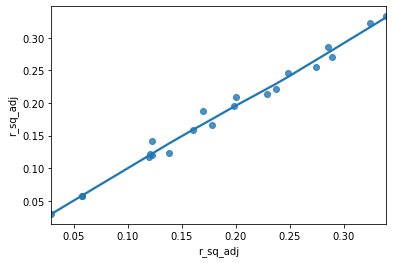

In [9]:
replication = result[result['cat']=='replication']
perturbation = result[result['cat']=='perturbation']

target = 'r_sq_adj'
x = sns.regplot(x= replication[target], y= perturbation[target], lowess=True)
print(replication[target].mean()-perturbation[target].mean())
print(stats.ttest_ind(replication[target].dropna(), 
                      perturbation[target].dropna(), equal_var=False))
np.corrcoef(replication[target].dropna(), perturbation[target].dropna())

Ttest_indResult(statistic=0.22221081644251553, pvalue=0.8253404708735629)
0.0032090147071204694


array([[1.        , 0.99091312],
       [0.99091312, 1.        ]])

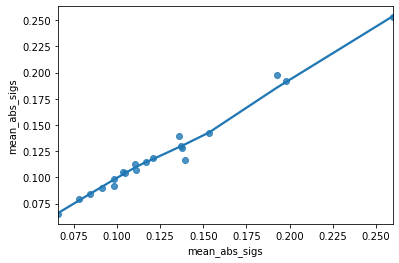

In [10]:
target = 'mean_abs_sigs'
x = sns.regplot(x= replication[target], y= perturbation[target], lowess=True)
print(stats.ttest_ind(replication[target].dropna(), 
                      perturbation[target].dropna(), equal_var=False))
print(replication[target].mean()-perturbation[target].mean())
np.corrcoef(replication[target].dropna(), perturbation[target].dropna())

In [ ]:
print(replication[target].mean()-perturbation[target].mean())

In [28]:
temp = pd.DataFrame({'X': list(replication[target].dropna()), 
                     'Y': list(perturbation[target].dropna()), 
                     'const': 1})
temp = temp[temp['Y']<=0.175]
temp['X'].mean()-temp['Y'].mean()

0.0033871672476443737

In [29]:
temp = pd.DataFrame({'X': list(replication[target].dropna()), 
                     'Y': list(perturbation[target].dropna()), 
                     'const': 1})
temp = temp[0.175<=temp['Y']]
temp['X'].mean()-temp['Y'].mean()

0.00219948364415129

(0.06, 0.15)

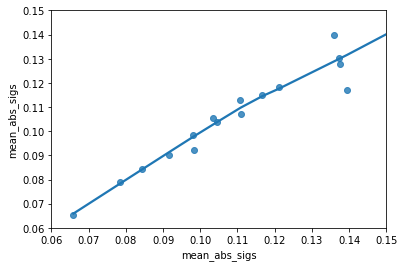

In [13]:
target = 'mean_abs_sigs'
x = sns.regplot(x= replication[target], y= perturbation[target], lowess=True)
plt.xlim(0.06, 0.15);plt.ylim(0.06, 0.15)

Ttest_indResult(statistic=0.25593266752342, pvalue=0.7991957618734988)
0.01937460467074137


array([[1.        , 0.94917518],
       [0.94917518, 1.        ]])

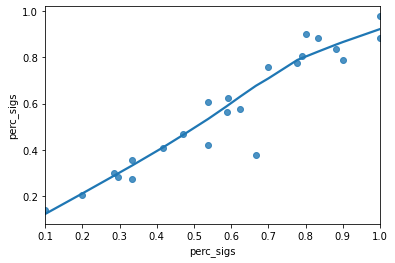

In [63]:
target = 'perc_sigs'
x = sns.regplot(x= replication[target], y= perturbation[target], lowess=True)

print(stats.ttest_ind(replication[target].dropna(), 
                      perturbation[target].dropna(), equal_var=False))

print(replication[target].mean()-perturbation[target].mean())

np.corrcoef(replication[target].dropna(), perturbation[target].dropna())

In [ ]:
#include all coefs in logit!